# Going Neural 

## on _word2vec_

Word2vec turns every word into a short list of numbers (a vector), learned from the words around it. Words used in similar contexts end up with similar vectors, so the vectors capture something of what the words mean.

This notebook trains word2vec from scratch on Terry Pratchett's *Going Postal*, written in PyTorch so every step is visible, and then explores what it learned.

<details>
<summary>Word2vec vs TF-IDF</summary>

TF-IDF and word2vec both turn text into vectors, but different ones.

+ **TF-IDF is a weighting scheme.** It *computes* one vector per **document**: in the Joist reviews notebook, every review got its own vector, one per word or word pair, from how often each term appears and how rare it is. Nothing is learned at this step; the sentiment classifier learned later.

+ **Word2vec is a model.** A small neural network is *trained* to predict nearby words, and learns one vector per **word**: here, every one of the 2,134 words got its own vector of 100 values (a word embedding). Words used in similar contexts get similar vectors; paragraphs and chapters get no vector of their own.

| | TF-IDF | Word2vec |
|---|---|---|
| **Vector size** | one dimension per vocabulary term, single words and word pairs (31,392 in the Joist reviews model) | small and fixed (100 here) |
| **How it's built** | counted: how often × how rare, then each document scaled to length 1; no learning | learned: a small network trained to predict nearby words |
| **Similar vectors mean** | the documents use the **same words** | the words appear in **similar contexts**, so they often mean similar things |
| **"letter" vs "mail"** | unrelated | close, because both appear near "post", "deliver" and "stamp" |
| **Explainable?** | yes: you can see which word weighed how much | not directly: single dimensions mean nothing on their own |
| **Needs** | any amount of text | a lot of text; one novel gives usable vectors only for common words |

**Geometrically:** TF-IDF places each document in a huge space with one named axis per word or word pair, so two documents are close only if they share words. Word2vec places each word in a small space where directions carry meaning. That's why vector arithmetic works here (the hero vs villain axis, the analogies) and doesn't with TF-IDF.

**Where both fall short:** each word gets one vector whatever its context, so "post" (the mail), "post" (a pole) and "post" (a job) share one. Contextual models such as BERT give every occurrence its own vector, based on the whole sentence.

</details>

<details>
<summary>How word2vec works (with formulas)</summary>

This notebook uses the **skip-gram** version with **negative sampling**, the standard form from the original word2vec papers.

**1. The task.** Read the book word by word. For each word (the *center* word), look at the words within a few positions on either side (its *context*). In "Moist licked the stamp", with a window of 2, the center word *licked* has the context words *Moist*, *the* and *stamp*. The model is trained to tell real (center, context) pairs from random ones.

**2. Two vectors per word.** Every word $w$ gets a center vector $\mathbf{v}_w$ and a context vector $\mathbf{u}_w$, each with $d$ numbers ($d = 100$ here). The score of a pair is their dot product, turned into a probability with the sigmoid $\sigma(x) = 1 / (1 + e^{-x})$:

$$
P(\text{real pair} \mid w, c) = \sigma(\mathbf{u}_c \cdot \mathbf{v}_w)
$$

**3. Negative sampling.** For each real pair, $k$ random "noise" words $n_1, \dots, n_k$ are drawn ($k = 5$ here). The model should score the real pair high and the noise pairs low. The loss for one pair is:

$$
L = -\log \sigma(\mathbf{u}_c \cdot \mathbf{v}_w) \;-\; \sum_{i=1}^{k} \log \sigma(-\mathbf{u}_{n_i} \cdot \mathbf{v}_w)
$$

Noise words are drawn in proportion to their frequency raised to the power 0.75, which gives rare words a slightly better chance than their raw frequency.

**4. Subsampling frequent words.** Very common words ("the", "and", "of") appear next to everything and say little. Each occurrence of a word with frequency $f(w)$ (its share of all words) is kept with probability

$$
P_{\text{keep}}(w) = \min\left(1,\; \sqrt{\frac{t}{f(w)}} + \frac{t}{f(w)}\right), \qquad t = 10^{-3}
$$

so frequent words are thinned out and rare words are always kept.

**5. The result.** After training, the center vectors $\mathbf{v}_w$ are the word vectors. Two words are compared with **cosine similarity**, the cosine of the angle between their vectors:

$$
\text{sim}(a, b) = \frac{\mathbf{v}_a \cdot \mathbf{v}_b}{\lVert \mathbf{v}_a \rVert \, \lVert \mathbf{v}_b \rVert}
$$

It is 1 for vectors pointing the same way, 0 for unrelated (perpendicular) ones and negative for opposite ones.

</details>

<details>
<summary>What this cell does</summary>

Loads the libraries and fixes the random seeds, so every run gives the same results.

</details>

In [1]:
import re
import random
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## 1. From book to words

<details>
<summary>What this cell does</summary>

Reads the book and splits it into words. Everything is lowercased, curly apostrophes are made straight, and possessive endings are removed, so "Moist's" counts as "moist". Words with an inner apostrophe or hyphen, such as "don't" or "ankh-morpork", stay whole.

</details>

In [2]:
text = open("./going_postal.txt", encoding="utf-8").read()

# lowercase, use one kind of apostrophe, then keep words made of letters,
# allowing inner apostrophes and hyphens ("don't", "ankh-morpork")
text = text.lower().replace("’", "'").replace("‘", "'")
words = re.findall(r"[a-z]+(?:['\-][a-z]+)*", text)
words = [re.sub(r"'s$", "", w) for w in words]      # "moist's" -> "moist"

print(f"{len(words):,} words in the book, {len(set(words)):,} different ones")
print(words[:30])

116,687 words in the book, 9,032 different ones
['the', 'year', 'prologue', 'the', 'flotillas', 'of', 'the', 'dead', 'sailed', 'around', 'the', 'world', 'on', 'underwater', 'rivers', 'very', 'nearly', 'nobody', 'knew', 'about', 'them', 'but', 'the', 'theory', 'is', 'easy', 'to', 'understand', 'it', 'runs']


## 2. Vocabulary

<details>
<summary>What this cell does</summary>

Keeps only words that appear at least 5 times, gives each one an ID number, and stores how often each appears. Rarer words are dropped because a handful of occurrences is not enough context to learn a reliable vector.

</details>

In [3]:
MIN_COUNT = 5        # words seen fewer times than this are dropped: too little context to learn from

counts = Counter(words)
vocab = [w for w, n in counts.most_common() if n >= MIN_COUNT]
word_to_id = {w: i for i, w in enumerate(vocab)}
freq = np.array([counts[w] for w in vocab], dtype=np.float64)

print(f"{len(vocab):,} words appear at least {MIN_COUNT} times")
print("most common:", vocab[:20])

2,134 words appear at least 5 times
most common: ['the', 'a', 'and', 'to', 'of', 'it', 'you', 'said', 'was', 'he', 'in', 'that', 'i', 'moist', 'his', 'on', 'mr', 'but', 'there', 'they']


<details>
<summary>What this cell does</summary>

Works out how likely each word is to be kept during training. Very common words such as "the" are kept only part of the time, because they appear next to everything and say little about meaning; rarer words are always kept. The book is then written as a list of word IDs.

</details>

In [4]:
T = 1e-3             # subsampling threshold

share = freq / freq.sum()
keep_prob = np.minimum(1.0, np.sqrt(T / share) + T / share)

ids = np.array([word_to_id[w] for w in words if w in word_to_id])
print(f"{len(ids):,} words left after dropping rare ones")
for w in ["the", "and", "moist", "gold", "letter"]:
    if w in word_to_id:
        print(f"  {w!r:10} appears {counts[w]:5,} times, kept with probability {keep_prob[word_to_id[w]]:.2f}")

105,480 words left after dropping rare ones
  'the'      appears 6,261 times, kept with probability 0.15
  'and'      appears 2,701 times, kept with probability 0.24
  'moist'    appears 1,266 times, kept with probability 0.37
  'gold'     appears    32 times, kept with probability 1.00
  'letter'   appears    70 times, kept with probability 1.00


## 3. Training pairs

<details>
<summary>What this cell does</summary>

Builds the training examples: for every word in the book, pairs of (center word, a word near it). The window is up to 5 words on each side, picked at random for each word, so closer neighbors count more often. Frequent words are thinned out first, as set up above. A new set of pairs is drawn for every pass over the book.

</details>

In [5]:
WINDOW = 5           # context words on each side

def make_pairs(ids, window=WINDOW):
    """(center, context) pairs for one pass over the book, after subsampling frequent words"""
    kept = ids[np.random.random(len(ids)) < keep_prob[ids]]
    centers, contexts = [], []
    for i, center in enumerate(kept):
        w = np.random.randint(1, window + 1)          # a random window size per word, as in word2vec
        for j in range(max(0, i - w), min(len(kept), i + w + 1)):
            if j != i:
                centers.append(center); contexts.append(kept[j])
    return torch.tensor(centers), torch.tensor(contexts)

centers, contexts = make_pairs(ids)
print(f"{len(centers):,} pairs in one pass, for example:")
for c, x in list(zip(centers, contexts))[:8]:
    print(f"  {vocab[c]:>12}  ->  {vocab[x]}")

445,212 pairs in one pass, for example:
          year  ->  dead
          year  ->  around
          year  ->  world
          year  ->  very
          year  ->  nearly
          dead  ->  year
          dead  ->  around
          dead  ->  world


<details>
<summary>What this cell does</summary>

Sets up how the random "noise" words are drawn: in proportion to each word's frequency to the power 0.75, which gives rare words a slightly better chance than their raw frequency would.

</details>

In [6]:
noise_probs = torch.tensor(freq ** 0.75 / (freq ** 0.75).sum(), dtype=torch.float32)
print("chance of each word being drawn as noise (top 5):",
      {vocab[i]: round(float(noise_probs[i]), 4) for i in range(5)})

chance of each word being drawn as noise (top 5): {'the': 0.0238, 'a': 0.0147, 'and': 0.0127, 'to': 0.0122, 'of': 0.0121}


## 4. The model

<details>
<summary>What this cell does</summary>

Defines the word2vec model: two tables of vectors, one for words as center words and one for words as context. For a batch of real pairs plus random noise words, it computes the negative-sampling loss from the formulas at the top: real pairs should get a high score, noise pairs a low one. Only the center vectors are kept at the end.

</details>

In [7]:
class SkipGram(nn.Module):
    def __init__(self, n_words, dim=100):
        super().__init__()
        self.center = nn.Embedding(n_words, dim)      # v_w: the word vectors we keep
        self.context = nn.Embedding(n_words, dim)     # u_c: used only during training
        nn.init.uniform_(self.center.weight, -0.5 / dim, 0.5 / dim)
        nn.init.zeros_(self.context.weight)

    def forward(self, center, context, noise):
        v = self.center(center)                       # [batch, dim]
        u = self.context(context)                     # [batch, dim]
        u_noise = self.context(noise)                 # [batch, k, dim]
        real = F.logsigmoid((u * v).sum(-1))                                   # log sigma(u_c . v_w)
        fake = F.logsigmoid(-torch.bmm(u_noise, v.unsqueeze(-1)).squeeze(-1))  # log sigma(-u_n . v_w)
        return -(real + fake.sum(-1)).mean()

model = SkipGram(len(vocab))
print(model)

SkipGram(
  (center): Embedding(2134, 100)
  (context): Embedding(2134, 100)
)


## 5. Training

<details>
<summary>What this cell does</summary>

Trains the model for 10 passes over the book. Each pass draws a fresh set of pairs, shuffles them and goes through them in batches of 1,024, each with 5 noise words per real pair. The loss should fall quickly in the first passes and then level off; a run takes a few minutes.

</details>

In [8]:
EPOCHS = 10          # passes over the book
BATCH = 1024
K_NOISE = 5          # noise words per real pair

opt = torch.optim.Adam(model.parameters(), lr=3e-3)
history = []
for epoch in range(EPOCHS):
    centers, contexts = make_pairs(ids)
    order = torch.randperm(len(centers))
    total, batches = 0.0, 0
    for start in range(0, len(order), BATCH):
        b = order[start:start + BATCH]
        noise = torch.multinomial(noise_probs, len(b) * K_NOISE, replacement=True).view(len(b), K_NOISE)
        loss = model(centers[b], contexts[b], noise)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item(); batches += 1
    history.append(total / batches)
    print(f"epoch {epoch + 1:2}: {len(centers):,} pairs, average loss {history[-1]:.3f}")

epoch  1: 446,742 pairs, average loss 2.805
epoch  2: 444,806 pairs, average loss 2.627
epoch  3: 446,305 pairs, average loss 2.572
epoch  4: 443,848 pairs, average loss 2.518
epoch  5: 443,542 pairs, average loss 2.470
epoch  6: 446,980 pairs, average loss 2.433
epoch  7: 446,198 pairs, average loss 2.402
epoch  8: 446,270 pairs, average loss 2.376
epoch  9: 445,435 pairs, average loss 2.352
epoch 10: 445,530 pairs, average loss 2.338


<details>
<summary>What this cell does</summary>

Plots the average loss for each pass, to check that training settled down.

</details>

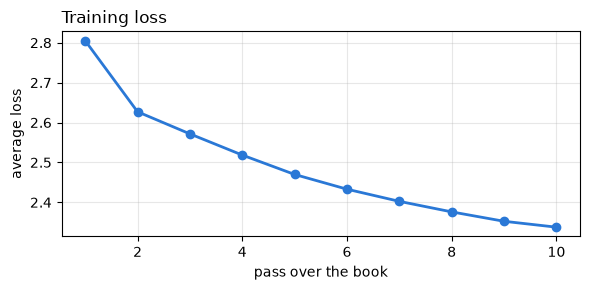

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 3))
plt.plot(range(1, len(history) + 1), history, marker="o", color="#2a78d6", linewidth=2)
plt.xlabel("pass over the book"); plt.ylabel("average loss")
plt.title("Training loss", loc="left"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. What the vectors learned

<details>
<summary>What this cell does</summary>

Lists, for a few words from the book, the words whose vectors point most nearly the same way, with their cosine similarity (1 means the same direction). Words used in similar places in the book should come out close: characters near characters, things you post near each other. Change the list to try other words; a word missing from the vocabulary appeared fewer than 5 times.

</details>

In [10]:
vectors = model.center.weight.detach()
unit = F.normalize(vectors, dim=1)                    # length 1, so dot product = cosine similarity
list_of_words = ["moist", "vetinari", "adora", "gold", "letter", "post", "clacks", "golem", "horse", "god", "money", "said"]

def nearest(word, n=8):
    if word not in word_to_id:
        return f"'{word}' is not in the vocabulary"
    sims = unit @ unit[word_to_id[word]]
    best = sims.argsort(descending=True)[1:n + 1]       # skip the word itself
    return ", ".join(f"{vocab[i]} ({sims[i]:.2f})" for i in best)

for w in list_of_words:
    print(f"{w:>9}: {nearest(w)}")

    moist: he (0.60), the (0.43), shook (0.43), tiddles (0.42), groat (0.42), said (0.41), she (0.41), nervously (0.41)
 vetinari: lord (0.78), slant (0.54), drumknott (0.52), eyebrow (0.49), tyrant (0.47), engineer (0.47), greenyham (0.44), pause (0.43)
    adora: belle (0.94), dearheart (0.66), miss (0.57), lid (0.51), cigarette (0.50), definite (0.49), feel (0.48), spike (0.48)
     gold: statue (0.58), suit (0.55), hat (0.55), golden (0.51), wings (0.49), shirt (0.47), mine (0.47), goddess (0.46)
   letter: address (0.49), delivered (0.48), sisters (0.48), k (0.46), envelope (0.44), spirit (0.44), box (0.43), arrive (0.42)
     post: office (0.79), regulations (0.51), oddly (0.50), crazy (0.48), rebuild (0.47), cellars (0.47), inkwells (0.46), property (0.46)
   clacks: towers (0.58), company (0.56), messages (0.55), codes (0.51), faster (0.48), snook (0.48), tower (0.47), continent (0.47)
    golem: rumbled (0.59), lipvig (0.55), hollow (0.43), correct (0.43), movement (0.42), pum

<details>
<summary>What this cell does</summary>

Compares specific pairs of words. Pairs that appear in similar contexts in the book should score higher than unrelated pairs.

</details>

In [11]:
word_pairs = [("letter", "mail"), ("letter", "stamp"), ("letter", "horse"), ("gold", "money"), ("moist", "vetinari"), ("day", "night")]

def similarity(a, b):
    if a not in word_to_id or b not in word_to_id:
        return None
    return float(unit[word_to_id[a]] @ unit[word_to_id[b]])

for a, b in word_pairs:
    s = similarity(a, b)
    print(f"{a:>8} vs {b:<9}", "not in vocabulary" if s is None else f"{s:.2f}")

  letter vs mail      0.24
  letter vs stamp     0.26
  letter vs horse     0.21
    gold vs money     0.24
   moist vs vetinari  0.36
     day vs night     0.26


<details>
<summary>What this cell does</summary>

Tries analogies of the form "a is to b as c is to ?": it takes the difference between two word vectors and adds it to a third. With vectors trained on billions of words this works well; with one novel only the most common relationships tend to work, so expect some misses.

</details>

In [12]:
words_analogy = [("man", "woman", "he"), ("he", "his", "she"), ("letter", "letters", "stamp"), ("day", "days", "year")]

def analogy(a, b, c, n=5):
    """a is to b as c is to ?  ->  words nearest to b - a + c"""
    if any(w not in word_to_id for w in (a, b, c)):
        return "a word is not in the vocabulary"
    target = F.normalize(unit[word_to_id[b]] - unit[word_to_id[a]] + unit[word_to_id[c]], dim=0)
    sims = unit @ target
    best = [i for i in sims.argsort(descending=True).tolist() if vocab[i] not in (a, b, c)][:n]
    return ", ".join(vocab[i] for i in best)

for a, b, c in words_analogy:
    print(f"{a} : {b} = {c} : ?   ->  {analogy(a, b, c)}")

man : woman = he : ?   ->  moist, added, perhaps, aggie, incidentally
he : his = she : ?   ->  her, opening, smiling, cigarette, expression
letter : letters = stamp : ?   ->  started, missing, stamps, one-dollar, penny
day : days = year : ?   ->  measured, early, ol, few, these


## 7. A map of the vocabulary

<details>
<summary>What this cell does</summary>

Draws the 100 most common words of the book (leaving out filler words such as "the" and "with") on a flat map. t-SNE squeezes the 100-number vectors into 2 dimensions while trying to keep words that were close in the full space close on the map, so groups of related words form clusters. Hover to see how often each word appears, and zoom in to read crowded areas. Distances between far-apart clusters are not meaningful on a t-SNE map; only the neighborhoods are.

</details>

In [23]:
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import plotly.graph_objects as go

N_MAP = 300
map_words = [w for w in vocab if w not in ENGLISH_STOP_WORDS and len(w) > 2][:N_MAP]
xy = TSNE(n_components=2, metric="cosine", perplexity=8, random_state=SEED, init="pca") \
        .fit_transform(unit[[word_to_id[w] for w in map_words]].numpy())

# size by frequency: square root, so the most common words don't swamp the map
freqs = np.array([counts[w] for w in map_words], dtype=float)
scaled = (np.sqrt(freqs) - np.sqrt(freqs.min())) / (np.sqrt(freqs.max()) - np.sqrt(freqs.min()))
dot_sizes = 10 + scaled * 35         # 10 to 45 px
text_sizes = 12 + scaled * 12        # 12 to 24 pt

# fit the view tightly around the words, with a small margin for labels
pad_x = (xy[:, 0].max() - xy[:, 0].min()) * 0.06
pad_y = (xy[:, 1].max() - xy[:, 1].min()) * 0.08

fig = go.Figure(go.Scatter(
    x=xy[:, 0], y=xy[:, 1], mode="markers+text", text=map_words, textposition="top center",
    textfont=dict(size=text_sizes, color="#52514e"),
    marker=dict(size=dot_sizes, color="#2a78d6", opacity=0.55, line=dict(width=1, color="#fcfcfb")),
    hovertext=[f"{w} ({counts[w]:,} times)" for w in map_words], hoverinfo="text"))
fig.update_layout(title=dict(text=f"The {N_MAP} most common content words, placed by their vectors "
                                  f"(bigger = more frequent in the book)", x=0.01),
                  height=650, paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb",
                  xaxis=dict(visible=False, range=[xy[:, 0].min() - pad_x, xy[:, 0].max() + pad_x]),
                  yaxis=dict(visible=False, range=[xy[:, 1].min() - pad_y, xy[:, 1].max() + pad_y * 1.5]),
                  margin=dict(l=10, r=10, t=50, b=10))
fig.show()

## 8. Let's try some vector arithmetic

Everything below uses only the word vectors trained above: no new training, just geometry.

<details>
<summary>What this cell does</summary>

Lists the main characters by the word the book uses most for each (Moist, Vetinari, Dearheart for Adora Belle, Gilt for Reacher Gilt, Pump for the golem Mr Pump, and so on), with a display name. Names and titles such as "mr" and "lord" are also collected, so the games below can leave them out when they look for ordinary words.

</details>

In [14]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

CHARACTERS = {
    "moist": "Moist", "vetinari": "Vetinari", "dearheart": "Adora Belle", "stanley": "Stanley",
    "groat": "Groat", "gilt": "Reacher Gilt", "pump": "Mr Pump", "drumknott": "Drumknott",
    "horsefry": "Horsefry", "greenyham": "Greenyham", "spools": "Spools", "igor": "Igor",
}
NAME_WORDS = set(CHARACTERS) | {"lipwig", "reacher", "adora", "belle", "von", "mr", "miss", "lord", "said"}
names = [n for n in CHARACTERS if n in word_to_id]
print("characters in the vocabulary:", ", ".join(CHARACTERS[n] for n in names))

characters in the vocabulary: Moist, Vetinari, Adora Belle, Stanley, Groat, Reacher Gilt, Mr Pump, Drumknott, Horsefry, Greenyham, Spools, Igor


### Who's like whom?

<details>
<summary>What this cell does</summary>

Compares every pair of main characters by how alike their vectors are, and draws it as a heatmap: the darker the cell, the more the two characters appear in similar kinds of passages. Characters who share scenes or roles (the bankers, the Post Office staff) should come out close. The three most and least alike pairs are printed below the chart.

</details>

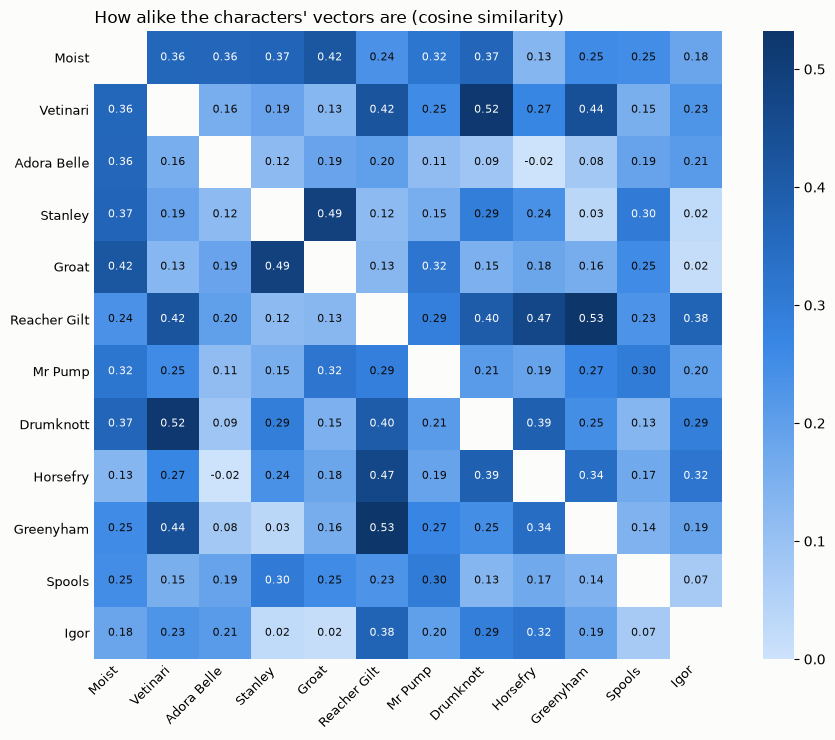

most alike: Reacher Gilt & Greenyham (0.53); Vetinari & Drumknott (0.52); Stanley & Groat (0.49)
least alike: Stanley & Igor (0.02); Groat & Igor (0.02); Adora Belle & Horsefry (-0.02)


In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb

M = (unit[[word_to_id[n] for n in names]] @ unit[[word_to_id[n] for n in names]].T).numpy()
np.fill_diagonal(M, np.nan)
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
blues.set_bad("#fcfcfb")
labels = [CHARACTERS[n] for n in names]
vmax = np.nanmax(M)

fig, ax = plt.subplots(figsize=(9, 7.5), facecolor="#fcfcfb")
im = ax.imshow(M, cmap=blues, vmin=0, vmax=vmax)
for i in range(len(names)):
    for j in range(len(names)):
        if i != j:
            r, g_, b = to_rgb(blues(M[i, j] / vmax))
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="#fcfcfb" if 0.2126 * r + 0.7152 * g_ + 0.0722 * b < 0.45 else "#0b0b0b")
ax.set_xticks(range(len(names)), labels, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(names)), labels, fontsize=9)
ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("How alike the characters' vectors are (cosine similarity)", loc="left", fontsize=12)
plt.colorbar(im, ax=ax, fraction=0.04).outline.set_visible(False)
plt.tight_layout(); plt.show()

pairs = sorted(((M[i, j], labels[i], labels[j]) for i in range(len(names)) for j in range(i + 1, len(names))), reverse=True)
print("most alike:", "; ".join(f"{a} & {b} ({s:.2f})" for s, a, b in pairs[:3]))
print("least alike:", "; ".join(f"{a} & {b} ({s:.2f})" for s, a, b in pairs[-3:]))

### Character cards

<details>
<summary>What this cell does</summary>

Gives each main character a "card": the 8 ordinary words whose vectors are nearest to theirs, leaving out filler words, other names and titles. These are the words the book tends to use in the same kinds of passages as the character, so they hint at each one's role, habits and surroundings.

</details>

In [16]:
def associated_words(word, n=8):
    """nearest ordinary words: no filler words, no names or titles"""
    sims = unit @ unit[word_to_id[word]]
    out = []
    for i in sims.argsort(descending=True).tolist():
        w = vocab[i]
        if w != word and w not in ENGLISH_STOP_WORDS and w not in NAME_WORDS and len(w) > 2:
            out.append(w)
        if len(out) == n:
            break
    return out

for n in names:
    print(f"{CHARACTERS[n]:>13}:  {', '.join(associated_words(n))}")

        Moist:  shook, tiddles, nervously, bewildered, scream, postmen, horrible, straightened
     Vetinari:  slant, eyebrow, tyrant, engineer, pause, realized, sharply, crispin
  Adora Belle:  maccalariat, cripslock, shrugged, cigarette, kills, leaning, father, john
      Stanley:  boy, glowed, apprentice, holes, pins, wow, push, waving
        Groat:  probationary, triumphantly, toupee, sir, senior, inspector, junior, cheerfully
 Reacher Gilt:  nutmeg, stowley, player, crispin, lordship, pony, rumours, board
      Mr Pump:  lipvig, rumbled, corner, shovel, paused, pottery, speak, eyebrow
    Drumknott:  clerk, brian, eyebrow, files, merely, glanced, ghost, thoughts
     Horsefry:  crispin, advice, poor, unusual, brandy, chap, indignation, goo
    Greenyham:  stowley, nutmeg, player, tyrant, slant, previous, pony, condition
       Spools:  teemer, twopenny, printed, express, handed, robinson, laughing, uncertainly
         Igor:  thur, glowbury, cook, crispin, personal, chap, wonderi

### Hero vs villain

<details>
<summary>What this cell does</summary>

Draws a line through the vectors from Reacher Gilt (the villain) to Moist (the hero) and places every word on it. Subtracting one vector from another gives a direction, here "more Moist, less Gilt", and each word's position along that direction shows which of the two it leans toward. It prints the 15 words furthest toward each end, then where every main character sits: positive numbers lean toward Moist, negative toward Gilt.

</details>

In [17]:
hero, villain = "moist", "gilt"
axis = F.normalize(unit[word_to_id[hero]] - unit[word_to_id[villain]], dim=0)
score = unit @ axis                                   # > 0 leans toward Moist, < 0 toward Gilt

ordinary = [i for i, w in enumerate(vocab) if w not in ENGLISH_STOP_WORDS and w not in NAME_WORDS and len(w) > 2]
ranked = sorted(ordinary, key=lambda i: float(score[i]))
print("Most on Reacher Gilt's side:", ", ".join(vocab[i] for i in ranked[:15]))
print("Most on Moist's side:       ", ", ".join(vocab[i] for i in ranked[::-1][:15]))
print()
for n in names:
    print(f"{CHARACTERS[n]:>13}: {float(score[word_to_id[n]]):+.2f}")

Most on Reacher Gilt's side: grateful, nutmeg, goo, player, personal, rumours, stowley, sent, affairs, fly, agree, respect, embezzlement, tyrant, grand
Most on Moist's side:        brushed, postmen, showed, rattle, useful, lights, kicked, straightened, blue, scream, eventually, colour, headed, horrible, fields

        Moist: +0.62
     Vetinari: -0.05
  Adora Belle: +0.13
      Stanley: +0.20
        Groat: +0.23
 Reacher Gilt: -0.62
      Mr Pump: +0.02
    Drumknott: -0.03
     Horsefry: -0.27
    Greenyham: -0.23
       Spools: +0.01
         Igor: -0.16


### Odd one out

<details>
<summary>What this cell does</summary>

A small quiz the vectors answer: in each group, which word fits least? For every word, it compares the word with the average of the others, and the one least like that average is the odd one out.

</details>

In [24]:
def odd_one_out(words):
    """the word least like the average of the others"""
    words = [w for w in words if w in word_to_id]
    vecs = unit[[word_to_id[w] for w in words]]
    scores = []
    for k in range(len(words)):
        others = F.normalize(torch.cat([vecs[:k], vecs[k + 1:]]).mean(0), dim=0)
        scores.append(float(vecs[k] @ others))
    return words[int(np.argmin(scores))]

QUIZ = [
    ["letter", "stamp", "envelope", "fresh"],
    ["vetinari", "drumknott", "lord", "golem"],
    ["gilt", "horsefry", "greenyham", "stanley"],
    ["clacks", "tower", "messages", "stamp"],
    ["gold", "money", "dollars", "angel"],
]
for words in QUIZ:
    print(f"{', '.join(words):40} ->  odd one out: {odd_one_out(words)}")

letter, stamp, envelope, fresh           ->  odd one out: fresh
vetinari, drumknott, lord, golem         ->  odd one out: golem
gilt, horsefry, greenyham, stanley       ->  odd one out: stanley
clacks, tower, messages, stamp           ->  odd one out: stamp
gold, money, dollars, angel              ->  odd one out: angel


### Word chains

<details>
<summary>What this cell does</summary>

Walks from one word to another through the vector space, one hop at a time. At each step it looks at the current word's 15 nearest neighbors (skipping filler words and words already visited) and moves to the one most like the goal. The chain shows a route of related words between two ideas. If it doesn't reach the goal within 10 hops, it says so.

</details>

In [19]:
def word_chain(start, goal, max_steps=10, neighbors=15):
    """hop from start toward goal, each step to the nearest neighbor that is most like the goal"""
    path, current = [start], start
    goal_vec = unit[word_to_id[goal]]
    for _ in range(max_steps):
        sims = unit @ unit[word_to_id[current]]
        options = [vocab[i] for i in sims.argsort(descending=True).tolist()[1:]
                   if vocab[i] not in path and vocab[i] not in ENGLISH_STOP_WORDS][:neighbors]
        if goal in options:
            path.append(goal); break
        current = max(options, key=lambda w: float(unit[word_to_id[w]] @ goal_vec))
        path.append(current)
    return " → ".join(path) + ("" if path[-1] == goal else "  (did not arrive)")

for a, b in [("letter", "gold"), ("stamp", "vetinari"), ("horse", "clacks"), ("moist", "dearheart")]:
    print(word_chain(a, b))

letter → address → god → gold
stamp → penny → seven → o'clock → pause → vetinari
horse → speed → clacks
moist → bewildered → leaning → dearheart


### Live explorer

<details>
<summary>What this cell does</summary>

A search box: type any word from the book and press Enter to see its 12 nearest words with their similarity.

</details>

In [20]:
import ipywidgets as widgets
from IPython.display import display

box = widgets.Text(placeholder="type a word, then press Enter", description="Word:", continuous_update=False)
result = widgets.HTML()

def show(change):
    w = change["new"].strip().lower()
    result.value = f"<pre style='white-space: pre-wrap'>{nearest(w, n=12)}</pre>" if w else ""

box.observe(show, names="value")
display(widgets.VBox([box, result]))

### Writing with word2vec

Can word2vec write? Not really: it never learned word order, only which words keep each other company. But it can still produce a stream of words that stays on topic.

<details>
<summary>What this cell does</summary>

Generates text word by word using only the trained vectors. At each step it averages the meaning of the last few words, mixed with the starting words so the text stays on topic, and picks a word that tends to appear **near** them in the book. Filler words such as "the" and recent repeats are skipped.

The result keeps to its topic but has no grammar, which shows what word2vec knows (which words belong together) and what it doesn't (how to build a sentence). Try other start words, or change `anchor` (higher stays closer to the topic), `temperature` (lower is more predictable) and `skip_filler`.

</details>

In [21]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def w2v_generate(start, n_words=40, window=4, temperature=0.5, anchor=0.5, avoid_repeats=8, skip_filler=True):
    words = [w for w in start.lower().split() if w in word_to_id]
    if not words:
        return "none of the start words are in the vocabulary"
    context_table = model.context.weight.detach()
    centers = model.center.weight.detach()
    start_vec = centers[[word_to_id[w] for w in words]].mean(0)    # the topic we started from
    blocked = {word_to_id[w] for w in ENGLISH_STOP_WORDS if w in word_to_id} if skip_filler else set()
    for _ in range(n_words):
        recent = [word_to_id[w] for w in words[-window:]]
        query = anchor * start_vec + (1 - anchor) * centers[recent].mean(0)   # stay near the topic, follow the last words
        scores = context_table @ query                              # how likely each word is to appear nearby
        for i in blocked | {word_to_id[w] for w in words[-avoid_repeats:]}:
            scores[i] = -1e9                                        # no filler words, no recent repeats
        probs = torch.softmax(scores / temperature, dim=0)
        words.append(vocab[int(torch.multinomial(probs, 1))])
    return " ".join(words)

torch.manual_seed(SEED)
for start in ["moist", "vetinari", "letter", "gold", "clacks tower", "dearheart"]:
    print(f"[{start}]  {w2v_generate(start)}\n")


[moist]  moist past alex life yard boris later dollars open given came figures understand lord mind stuck hand gryle raise stamp probably gold say postmaster suit instantly upwright world timber pointy screamed final course boris letters going laughing maybe stuck leg completely

[vetinari]  vetinari previous lord presence tapped known rule extremely rumour tyrant eyebrow advice ways greenyham raised smiling faint offer quite inner moving smiled looks play sorry leaned greenyham stones slant lord exactly rule tyrant i'm bloody prospect greenyham probably watch protested hmm

[letter]  letter spirit k lowering tried cigarette metal body aggie gets letter real box strange headed delivered tomorrow right broom letter window points counter sisters years pence box said letter use send reacher straight priest frau liked stuff dolly letter sisters real

[gold]  gold hat wings wow rainwater honest use dream customers gold suit slight extra hat golden silly working smiled gold wizards rain stat